# Multi-Label Emotion Detection Using NLP

This notebook demonstrates a structured approach to multi-label emotion
classification using both traditional ML and transformer-based models.
We’ll analyze text data and predict which emotions are expressed, with
each text potentially having multiple emotion labels.

## Overview
1. Import Libraries, Configuration, and Utilities
2. Data Loading & Quick EDA
3. Text Pre-Processing
4. Traditional ML Baselines
5. Transformer Models
6. Compare Results
7. Conclusion

## 1. Import Libraries, Configuration, and Utilities
Here we import libraries, and define constants used
throughout the notebook. We also define utility functions for model.

### 1.1. Import Libraries

In [1]:
# Import necessary libraries
import re
import string

import emoji
import matplotlib.pyplot as plt
# NLP and preprocessing
import nltk
import numpy as np
import pandas as pd
import seaborn as sns
from datasets import Dataset
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize
# Machine learning
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, hamming_loss, f1_score, jaccard_score)
from sklearn.model_selection import train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.naive_bayes import MultinomialNB
# Deep learning
import torch
from torch import nn
import  transformers
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding
)

/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Download necessary NLTK resources
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('stopwords')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to /Users/hsamadov/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/hsamadov/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/hsamadov/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/hsamadov/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/hsamadov/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [3]:
# Force using slow tokenizers when needed
transformers.utils.TOKENIZERS_PARALLELISM = False
transformers.utils.SLOW_TOKENIZER_MAPPING = None

In [4]:
# Check for GPU availability
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print('Using device:', device)

Using device: cpu


### 1.2. Configuration Parameters

In [5]:
# Global configuration parameters
RANDOM_STATE = 42
MAX_LEN = 256  # Maximum sequence length for transformers: 128, 256, or 512
TEST_SIZE = 0.2
TRAIN_BATCH_SIZE = 16
EVAL_BATCH_SIZE = 16
LEARNING_RATE = 2e-5
NUM_TRAIN_EPOCHS = 5 # Number of training epochs
WEIGHT_DECAY = 0.01 # Default: 0.0, Given: 0.01
WARMUP_RATIO = 0.1 # Default: 0.0, Given: 0.1
LR_SCHEDULER_TYPE = 'linear'  # Options: 'linear', 'cosine', 'cosine_with_restarts', 'polynomial', 'constant', 'constant_with_warmup'

In [6]:
# Emotion labels we're predicting
EMOTIONS = ['anger', 'fear', 'joy', 'sadness', 'surprise']

In [7]:
# Define which transformer models to benchmark
TRANSFORMER_MODELS = [
    'roberta-base',
    'bert-base-uncased',
    'distilbert-base-uncased',
    'cardiffnlp/twitter-roberta-base-emotion-multilabel-latest',
    'j-hartmann/emotion-english-distilroberta-base'
]

# Define traditional ML model components for grid search
VECTORIZERS = {
    "count_uni": {"type": "count", "ngram_range": (1, 1)},
    "tfidf_uni": {"type": "tfidf", "ngram_range": (1, 1)},
    "tfidf_bi": {"type": "tfidf", "ngram_range": (1, 2)}
}

CLASSIFIERS = {
    "mnb": {"model": "naive_bayes"},
    "logreg": {"model": "logistic_regression", "max_iter": 200, "class_weight": "balanced"}
}

### 1.3. Utility Functions

In [8]:
def compute_metrics(y_true, y_pred, threshold=0.5, verbose=False):
    """
    Compute comprehensive metrics for multi-label classification

    Parameters:
        y_true (ndarray): Ground truth labels
        y_pred (ndarray): Predicted probabilities or binary predictions
        threshold (float): Threshold for converting probabilities to binary predictions
        verbose (bool): Whether to print detailed classification report

    Returns:
        dict: Dictionary containing various evaluation metrics
    """
    # Convert probabilities to binary predictions if needed
    if not isinstance(y_pred[0][0], (np.int64, np.int32, int, bool)):
        y_pred_binary = (y_pred >= threshold).astype(int)
    else:
        y_pred_binary = y_pred

    # Calculate metrics
    metrics = {
        "hamming_loss": hamming_loss(y_true, y_pred_binary),
        "exact_match": np.all(y_true == y_pred_binary, axis=1).mean(),
        "f1_micro": f1_score(y_true, y_pred_binary, average="micro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred_binary, average="macro", zero_division=0),
        "jaccard_micro": jaccard_score(y_true, y_pred_binary, average="micro", zero_division=0),
        "jaccard_macro": jaccard_score(y_true, y_pred_binary, average="macro", zero_division=0)
    }

    if verbose:
        print(classification_report(y_true, y_pred_binary, target_names=EMOTIONS, zero_division=0))
        print(f"Exact Match Accuracy: {metrics['exact_match']:.4f}")

    return metrics

In [9]:
# Adapter for HuggingFace Trainer
def compute_metrics_for_trainer(eval_pred):
    """Adapter for the HuggingFace Trainer's compute_metrics parameter"""
    logits, labels = eval_pred
    probs = torch.sigmoid(torch.tensor(logits)).cpu().numpy()
    preds = (probs >= 0.5).astype(int)

    # Calculate and print detailed metrics
    metrics = compute_metrics(labels, preds, verbose=True)
    return metrics

## 2. Data Loading & Quick EDA

In [10]:
# Load the dataset
df = pd.read_csv(r"data/main.csv")

# Display the first few rows to understand the data structure
df.head()

,id,text,anger,fear,joy,sadness,surprise
0,eng_train_track_a_00001,"Colorado, middle of nowhere.",0,1,0,0,1
1,eng_train_track_a_00002,This involved swimming a pretty large lake tha...,0,1,0,0,0
2,eng_train_track_a_00003,It was one of my most shameful experiences.,0,1,0,1,0
3,eng_train_track_a_00004,"After all, I had vegetables coming out my ears...",0,0,0,0,0
4,eng_train_track_a_00005,Then the screaming started.,0,1,0,1,1


In [11]:
# Calculate absolute counts for each emotion
emotion_counts = {emotion: df[emotion].sum() for emotion in EMOTIONS}
total_entries = len(df)

# Calculate percentage distribution
emotion_percentages = {emotion: (count / total_entries) * 100
                       for emotion, count in emotion_counts.items()}

# Display distribution statistics
print("Emotion Distribution Analysis")
print("=" * 30)
print(f"Total entries: {total_entries}\n")

print("Absolute counts:")
for emotion, count in emotion_counts.items():
    print(f"{emotion.capitalize()}: {count}")

print("\nPercentages:")
for emotion, percentage in emotion_percentages.items():
    print(f"{emotion.capitalize()}: {percentage:.2f}%")

Emotion Distribution Analysis
Total entries: 2768

Absolute counts:
Anger: 333
Fear: 1611
Joy: 674
Sadness: 878
Surprise: 839

Percentages:
Anger: 12.03%
Fear: 58.20%
Joy: 24.35%
Sadness: 31.72%
Surprise: 30.31%


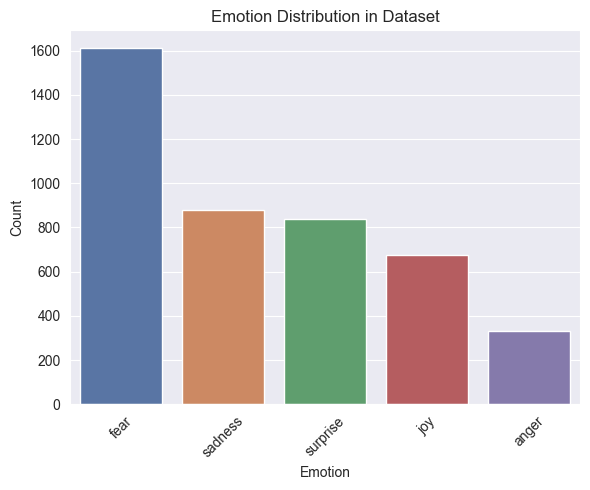

In [12]:
# Visualize emotion distribution
plt.figure(figsize=(6, 5))
emotion_df = pd.DataFrame(list(emotion_counts.items()), columns=['Emotion', 'Count'])
emotion_df = emotion_df.sort_values(by=['Count'], ascending=False)
sns.barplot(x='Emotion', y='Count', hue='Emotion', data=emotion_df, palette='deep', legend=False)
plt.title('Emotion Distribution in Dataset')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

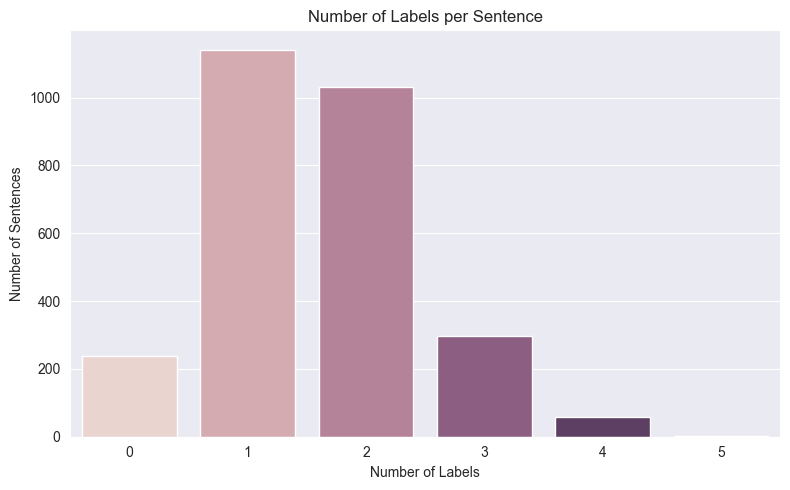

In [13]:
# Count how many labels each sentence has
df["num_labels"] = df[EMOTIONS].sum(axis=1)
multilabel_sentences = df["num_labels"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
sns.barplot(x=multilabel_sentences.index, y=multilabel_sentences.values, hue=multilabel_sentences.index, legend=False)
plt.title("Number of Labels per Sentence")
plt.xlabel("Number of Labels")
plt.ylabel("Number of Sentences")
plt.tight_layout()
plt.show()

count    2768.000000
mean       15.477601
std        10.856667
min         1.000000
25%         8.000000
50%        13.000000
75%        20.000000
max        89.000000
Name: token_count, dtype: float64


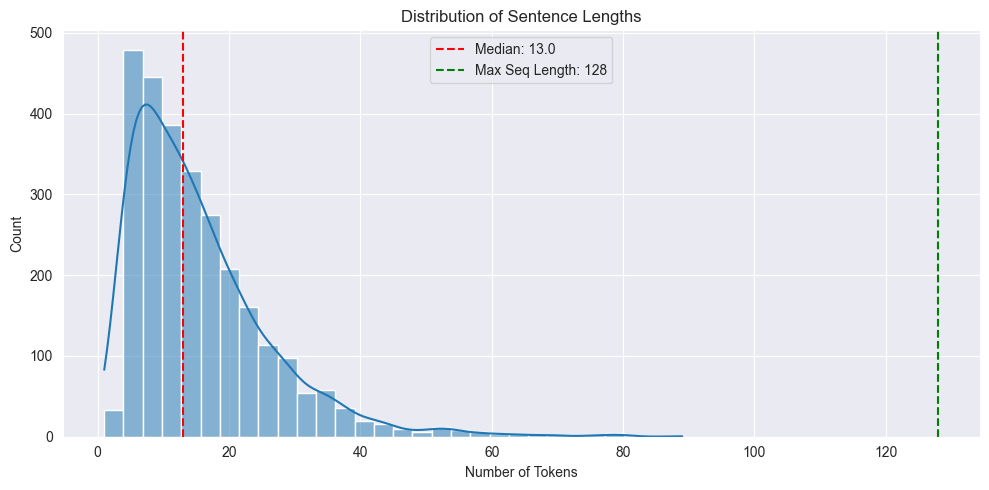

In [14]:
# Analyze text length distribution
df["token_count"] = df["text"].apply(lambda x: len(str(x).split()))
print(df["token_count"].describe())

plt.figure(figsize=(10, 5))
sns.histplot(df["token_count"], bins=30, kde=True)
plt.title("Distribution of Sentence Lengths")
plt.xlabel("Number of Tokens")
plt.ylabel("Count")
plt.axvline(x=df["token_count"].median(), color='red', linestyle='--', label=f'Median: {df["token_count"].median()}')
plt.axvline(x=128, color='green', linestyle='--', label='Max Seq Length: 128')
plt.legend()
plt.tight_layout()
plt.show()

## 3. Text Pre-Processing
We'll prepare the text data for modeling through several steps:
1. Cleaning (lowercase, remove URLs, mentions, special characters)
2. Tokenization
3. Stop word removal
4. Stemming

In [15]:
# Initialize stopwords and stemmer
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

# Prepare 'labels' column as a list for HuggingFace Dataset compatibility
df['labels'] = df[EMOTIONS].values.tolist()

In [16]:
def clean_text(text):
    """
    Basic text cleaning: lowercase, remove URLs, mentions, emojis and punctuation

    Args:
        text (str): Raw text input

    Returns:
        str: Cleaned text
    """
    text = str(text).lower()
    text = emoji.demojize(text, delimiters=(" ", " "))
    text = re.sub(r'https?://\S+|www\.[a-zA-Z0-9./]+', ' ', text)
    text = re.sub(r'@[A-Za-z0-9_]+', ' ', text)
    text = re.sub(r'[%s]' % re.escape(string.punctuation), ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

In [17]:
def preprocess(text):
    """
    Advanced preprocessing: tokenization, stopword removal, and stemming

    Args:
        text (str): Raw or cleaned text

    Returns:
        str: Fully preprocessed text
    """
    # Ensure text is string and lowercase
    text = str(text).lower()

    # Tokenize
    tokens = word_tokenize(text)

    # Remove punctuation and stopwords, then apply stemming
    tokens = [stemmer.stem(word) for word in tokens
              if word not in string.punctuation and word not in stop_words]

    # Join tokens back into a single string
    return " ".join(tokens)

In [18]:
# Apply both cleaning functions to create different versions of the text
df['clean_text'] = df['text'].apply(clean_text)
df['processed_text'] = df['text'].apply(preprocess)

In [19]:
# Display examples to verify preprocessing
display_cols = ['text', 'clean_text', 'processed_text']
print("Original vs Cleaned vs Processed Text Examples:")
df[display_cols].head(3)

Original vs Cleaned vs Processed Text Examples:


,text,clean_text,processed_text
0,"Colorado, middle of nowhere.",colorado middle of nowhere,colorado middl nowher
1,This involved swimming a pretty large lake tha...,this involved swimming a pretty large lake tha...,involv swim pretti larg lake head
2,It was one of my most shameful experiences.,it was one of my most shameful experiences,one shame experi


## 4. Traditional ML Baselines

We'll implement several traditional machine learning models as baselines:
- Compare different text vectorization approaches (Count, TF-IDF)
- Evaluate multiple classification algorithms
- Use a systematic grid search approach

### 4.1. Define model grid

In [20]:
# Split data into training and validation sets
train_df, val_df = train_test_split(df, test_size=TEST_SIZE, random_state=RANDOM_STATE)


In [21]:
# Define vectorizer factory
def get_vectorizer(config):
    """Create a vectorizer based on configuration"""
    if config["type"] == "count":
        return CountVectorizer(ngram_range=config["ngram_range"])
    elif config["type"] == "tfidf":
        return TfidfVectorizer(
            ngram_range=config["ngram_range"],
            min_df=2,
            max_df=0.9,
            sublinear_tf=True
        )
    else:
        raise ValueError(f"Unknown vectorizer type: {config['type']}")


# Define classifier factory
def get_classifier(config):
    """Create a classifier based on configuration"""
    if config["model"] == "naive_bayes":
        return MultinomialNB()
    elif config["model"] == "logistic_regression":
        return LogisticRegression(
            max_iter=config.get("max_iter", 100),
            class_weight=config.get("class_weight", None),
            solver='liblinear'
        )
    else:
        raise ValueError(f"Unknown classifier type: {config['model']}")

### 4.2. Grid evaluation loop

In [22]:
# Initialize results storage
traditional_ml_results = []

# Run all combinations of vectorizers and classifiers
for vec_name, vec_config in VECTORIZERS.items():
    # Create and fit vectorizer
    vectorizer = get_vectorizer(vec_config)
    X_train = vectorizer.fit_transform(train_df['processed_text'])
    X_val = vectorizer.transform(val_df['processed_text'])

    y_train = train_df[EMOTIONS].values
    y_val = val_df[EMOTIONS].values

    for clf_name, clf_config in CLASSIFIERS.items():
        print(f"\nTraining: {vec_name} + {clf_name}")

        # Create and train classifier
        classifier = OneVsRestClassifier(get_classifier(clf_config))
        classifier.fit(X_train, y_train)

        # Generate and evaluate predictions
        y_pred = classifier.predict(X_val)

        # Add results with model identifier
        metrics = compute_metrics(y_val, y_pred, verbose=True)
        metrics['model'] = f"{vec_name}+{clf_name}"
        traditional_ml_results.append(metrics)


Training: count_uni + mnb
              precision    recall  f1-score   support

       anger       0.25      0.03      0.05        72
        fear       0.68      0.80      0.74       330
         joy       0.59      0.26      0.36       115
     sadness       0.56      0.36      0.44       167
    surprise       0.56      0.31      0.40       179

   micro avg       0.63      0.48      0.54       863
   macro avg       0.53      0.35      0.40       863
weighted avg       0.58      0.48      0.50       863
 samples avg       0.53      0.44      0.45       863

Exact Match Accuracy: 0.2437

Training: count_uni + logreg
              precision    recall  f1-score   support

       anger       0.37      0.33      0.35        72
        fear       0.68      0.61      0.64       330
         joy       0.42      0.49      0.45       115
     sadness       0.49      0.49      0.49       167
    surprise       0.52      0.61      0.56       179

   micro avg       0.54      0.55      0.54  

In [23]:
# Format results as DataFrame for easier comparison
traditional_results_df = pd.DataFrame(traditional_ml_results)
display(traditional_results_df[['model', 'f1_micro', 'f1_macro', 'exact_match']]
        .sort_values('f1_micro', ascending=False))

,model,f1_micro,f1_macro,exact_match
5,tfidf_bi+logreg,0.557955,0.517181,0.232852
1,count_uni+logreg,0.544406,0.498648,0.236462
0,count_uni+mnb,0.543177,0.396525,0.243682
3,tfidf_uni+logreg,0.540782,0.494380,0.200361
2,tfidf_uni+mnb,0.507959,0.292075,0.222022
4,tfidf_bi+mnb,0.502557,0.269962,0.209386


## 5. Transformer Models

Now we'll implement transformer-based approaches using HuggingFace's Transformers library.
We'll compare multiple pre-trained models on our multi-label emotion detection task.


In [24]:
def prepare_hf_dataset(pandas_df, tokenizer):
    """
    Prepare a HuggingFace Dataset from a pandas DataFrame

    Args:
        pandas_df: DataFrame with text and labels
        tokenizer: HuggingFace tokenizer

    Returns:
        Dataset: Ready-to-use HuggingFace Dataset
    """
    # Create a copy to avoid modifying the original
    df_copy = pandas_df.copy()

    # Ensure labels are properly formatted as float lists
    df_copy['labels'] = df_copy['labels'].apply(lambda x: [float(label) for label in x])

    # Create dataset from pandas
    ds = Dataset.from_pandas(df_copy[['clean_text', 'labels']])
    ds = ds.rename_column('clean_text', 'text')

    # Define tokenization function
    def tokenize(batch):
        # Tokenize texts
        encodings = tokenizer(
            batch['text'],
            truncation=True,
            padding='max_length',
            max_length=MAX_LEN,
            return_tensors=None
        )

        # Update batch with tokenized data
        batch.update(encodings)
        return batch

    # Apply tokenization
    ds = ds.map(tokenize, batched=True, remove_columns=['text'])

    # Set format to PyTorch tensors
    ds.set_format(
        type='torch',
        columns=['input_ids', 'attention_mask', 'labels'],
        output_all_columns=False
    )

    return ds

### 5.0. Prepare Weighted Loss

In [25]:
label_counts = train_df[EMOTIONS].sum()
total = len(train_df)
neg_counts = total - label_counts
pos_weight = (neg_counts / label_counts).values
pos_weight = torch.tensor(pos_weight, dtype=torch.float).to(device)

In [26]:
class WeightedLossModel(nn.Module):
    def __init__(self, model_name, num_labels, pos_weight):
        super().__init__()
        self.model = AutoModelForSequenceClassification.from_pretrained(
            model_name,
            num_labels=num_labels,
            problem_type="multi_label_classification",
            ignore_mismatched_sizes=True
        )
        self.pos_weight = pos_weight

    def forward(self, input_ids=None, attention_mask=None, labels=None, **kwargs):
        # print("Got kwargs:", kwargs.keys())
        # Only pass known args to the transformer model
        model_outputs = self.model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        logits = model_outputs.logits
        loss = None

        if labels is not None:
            # Ensure pos_weight is on the same device as logits
            if self.pos_weight.device != logits.device:
                self.pos_weight = self.pos_weight.to(logits.device)

            # Also ensure labels are on the same device
            labels = labels.to(logits.device)

            # Compute weighted BCE loss
            loss_fn = nn.BCEWithLogitsLoss(pos_weight=self.pos_weight)
            loss = loss_fn(logits, labels.float())


        # Return a dict matching HuggingFace expectations
        return {
            "loss": loss,
            "logits": logits
        }

### 5.1. Benchmark a list of models

In [27]:
# Initialize results storage for transformer models
raw_eval_results = []
transformer_results = []

In [28]:
def run_experiment(model, variant_tag, model_name):
    tag = f"{model_name.split('/')[-1]}_{variant_tag}"
    output_dir = f"results/{tag}_out"

    args = TrainingArguments(
        output_dir=output_dir,
        eval_strategy="epoch",
        save_strategy="epoch",
        learning_rate=LEARNING_RATE,
        per_device_train_batch_size=TRAIN_BATCH_SIZE,
        per_device_eval_batch_size=EVAL_BATCH_SIZE,
        num_train_epochs=NUM_TRAIN_EPOCHS,
        weight_decay=WEIGHT_DECAY,
        warmup_ratio=WARMUP_RATIO,
        lr_scheduler_type=LR_SCHEDULER_TYPE,
        load_best_model_at_end=True,
        metric_for_best_model="f1_micro",
        greater_is_better=True,
    )

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        tokenizer=tokenizer,
        data_collator=DataCollatorWithPadding(tokenizer),
        compute_metrics=compute_metrics_for_trainer,
    )

    trainer.train()
    eval_res = trainer.evaluate()
    trainer.save_model(output_dir)
    print(f"✅ {tag} saved to {output_dir}")

    # book-keeping
    raw_eval_results.append({"model": tag, "results": eval_res})
    transformer_results.append({
        "model": tag,
        "f1_micro": eval_res.get("eval_f1_micro", float("nan")),
        "f1_macro": eval_res.get("eval_f1_macro", float("nan")),
        "exact_match": eval_res.get("eval_exact_match", float("nan")),
        "hamming_loss": eval_res.get("eval_hamming_loss", float("nan")),
        "epoch": NUM_TRAIN_EPOCHS,
    })

In [29]:
pos_weight = pos_weight.to(device)

In [30]:
for model_name in TRANSFORMER_MODELS:
    print(f"\n{'='*80}\nTraining base: {model_name}\n{'='*80}")

    # Tokenizer + datasets
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    train_ds = prepare_hf_dataset(train_df, tokenizer)
    val_ds   = prepare_hf_dataset(val_df, tokenizer)

    # -------- Variant 1: vanilla ----------------------------------
    vanilla_model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=len(EMOTIONS),
        problem_type="multi_label_classification",
        ignore_mismatched_sizes=True,
    ).to(device)


    # -------- Variant 2: weighted ---------------------------------
    weighted_model = WeightedLossModel(
        model_name=model_name,
        num_labels=len(EMOTIONS),
        pos_weight=pos_weight,
    ).to(device)

    # Run experiments for both variants
    run_experiment(vanilla_model, "vanilla", model_name)
    run_experiment(weighted_model, "weighted", model_name)



Training base: roberta-base


Map: 100%|██████████| 554/554 [00:00<00:00, 25588.54 examples/s]
Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/var/folders/pk/gpx4lq8j573591mg397r1tkh0000gn/T/ipykernel_3509/193557494.py:21: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead

Epoch,Training Loss,Validation Loss,Hamming Loss,Exact Match,F1 Micro,F1 Macro,Jaccard Micro,Jaccard Macro,Runtime,Samples Per Second,Steps Per Second
1,No log,0.426305,0.191697,0.361011,0.649967,0.509654,0.481445,0.381373,8.072400,68.629000,4.336000
2,No log,0.386304,0.178339,0.398917,0.687737,0.632689,0.524085,0.472389,8.124800,68.186000,4.308000
3,No log,0.380908,0.159567,0.449458,0.740914,0.701875,0.588454,0.545835,8.220200,67.395000,4.258000
4,0.382000,0.380952,0.161733,0.447653,0.736160,0.698354,0.582479,0.541393,7.762600,71.367000,4.509000
5,0.382000,0.379518,0.161372,0.449458,0.731854,0.688937,0.577105,0.531413,7.738500,71.590000,4.523000


              precision    recall  f1-score   support

       anger       0.00      0.00      0.00        72
        fear       0.80      0.80      0.80       330
         joy       0.59      0.70      0.64       115
     sadness       0.78      0.37      0.50       167
    surprise       0.79      0.49      0.60       179

   micro avg       0.75      0.57      0.65       863
   macro avg       0.59      0.47      0.51       863
weighted avg       0.70      0.57      0.61       863
 samples avg       0.63      0.53      0.56       863

Exact Match Accuracy: 0.3610


/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:683: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


...

              precision    recall  f1-score   support

       anger       0.46      0.61      0.52        72
        fear       0.76      0.76      0.76       330
         joy       0.52      0.76      0.62       115
     sadness       0.55      0.73      0.63       167
    surprise       0.62      0.75      0.68       179

   micro avg       0.62      0.74      0.67       863
   macro avg       0.58      0.72      0.64       863
weighted avg       0.63      0.74      0.68       863
 samples avg       0.60      0.68      0.61       863

Exact Match Accuracy: 0.3267


/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:683: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


              precision    recall  f1-score   support

       anger       0.49      0.58      0.54        72
        fear       0.74      0.79      0.76       330
         joy       0.59      0.74      0.66       115
     sadness       0.55      0.75      0.64       167
    surprise       0.66      0.73      0.69       179

   micro avg       0.64      0.75      0.69       863
   macro avg       0.61      0.72      0.66       863
weighted avg       0.65      0.75      0.69       863
 samples avg       0.62      0.68      0.62       863

Exact Match Accuracy: 0.3394


/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:683: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


              precision    recall  f1-score   support

       anger       0.49      0.58      0.54        72
        fear       0.74      0.79      0.76       330
         joy       0.59      0.74      0.66       115
     sadness       0.55      0.75      0.64       167
    surprise       0.66      0.73      0.69       179

   micro avg       0.64      0.75      0.69       863
   macro avg       0.61      0.72      0.66       863
weighted avg       0.65      0.75      0.69       863
 samples avg       0.62      0.68      0.62       863

Exact Match Accuracy: 0.3394
✅ emotion-english-distilroberta-base_weighted saved to results/emotion-english-distilroberta-base_weighted_out


In [31]:
print(transformer_results)

[{'model': 'roberta-base_vanilla', 'f1_micro': 0.7409144196951934, 'f1_macro': 0.7018745367439607, 'exact_match': 0.44945848375451264, 'hamming_loss': 0.1595667870036101, 'epoch': 5}, {'model': 'roberta-base_weighted', 'f1_micro': 0.7245575221238938, 'f1_macro': 0.6960278828254658, 'exact_match': 0.40794223826714804, 'hamming_loss': 0.17978339350180506, 'epoch': 5}, {'model': 'bert-base-uncased_vanilla', 'f1_micro': 0.7234553089382123, 'f1_macro': 0.6716206789601856, 'exact_match': 0.4043321299638989, 'hamming_loss': 0.1664259927797834, 'epoch': 5}, {'model': 'bert-base-uncased_weighted', 'f1_micro': 0.7153123272526257, 'f1_macro': 0.6747153075470471, 'exact_match': 0.3935018050541516, 'hamming_loss': 0.18592057761732853, 'epoch': 5}, {'model': 'distilbert-base-uncased_vanilla', 'f1_micro': 0.6855733662145499, 'f1_macro': 0.6348641175486095, 'exact_match': 0.36823104693140796, 'hamming_loss': 0.18411552346570398, 'epoch': 5}, {'model': 'distilbert-base-uncased_weighted', 'f1_micro': 0.

In [32]:
# Threshold Tuning for Transformer Model
print("\n========== Threshold Tuning ==========")

# Get the best model name and details
best_model_info = max(transformer_results, key=lambda x: x['f1_micro'])
best_model_name = best_model_info['model']
print(f"Tuning thresholds for best model: {best_model_name}")

# Load the best model and create a trainer for it
best_model_path = f"results/{best_model_name}_out"
tokenizer = AutoTokenizer.from_pretrained(best_model_path)
model = AutoModelForSequenceClassification.from_pretrained(best_model_path).to(device)

# Recreate the validation dataset using the best model's tokenizer
val_ds = prepare_hf_dataset(val_df, tokenizer)

# Create trainer instance for the best model
trainer = Trainer(
    model=model,
    tokenizer=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics_for_trainer
)

# Get raw predictions (logits) and labels from validation set
pred_logits, true_labels, _ = trainer.predict(val_ds)

# Convert logits to sigmoid probabilities
probs = torch.sigmoid(torch.tensor(pred_logits)).numpy()

# Ground truth as array
true_labels = np.array(true_labels)


========== Threshold Tuning ==========
Tuning thresholds for best model: roberta-base_vanilla


Map: 100%|██████████| 554/554 [00:00<00:00, 24515.41 examples/s]
/var/folders/pk/gpx4lq8j573591mg397r1tkh0000gn/T/ipykernel_3509/807659603.py:18: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
/Users/hsamadov/Library/Caches/pypoetry/virtualenvs/nlp-emotion-detection-JtJBIgvt-py3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:683: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


              precision    recall  f1-score   support

       anger       0.76      0.51      0.61        72
        fear       0.82      0.85      0.83       330
         joy       0.60      0.72      0.66       115
     sadness       0.74      0.66      0.70       167
    surprise       0.75      0.69      0.72       179

   micro avg       0.75      0.73      0.74       863
   macro avg       0.73      0.69      0.70       863
weighted avg       0.75      0.73      0.74       863
 samples avg       0.68      0.67      0.65       863

Exact Match Accuracy: 0.4495


In [33]:
# Grid search for best global threshold
thresholds = np.linspace(0.1, 0.9, 17)
best_threshold = 0.5
best_f1 = 0

for t in thresholds:
    preds = (probs > t).astype(int)
    f1 = f1_score(true_labels, preds, average='micro')
    if f1 > best_f1:
        best_f1 = f1
        best_threshold = t

print(f"Best global threshold: {best_threshold:.2f} with F1 score: {best_f1:.4f}")

# Per-label threshold optimization
best_thresholds = []
best_f1_per_label = []

print("\nOptimal thresholds per emotion:")
for i in range(len(EMOTIONS)):
    best_t = 0.5
    best_f1 = 0

    for t in thresholds:
        pred_i = (probs[:, i] > t).astype(int)
        f1 = f1_score(true_labels[:, i], pred_i, average='binary')
        if f1 > best_f1:
            best_f1 = f1
            best_t = t

    best_thresholds.append(best_t)
    best_f1_per_label.append(best_f1)
    print(f"{EMOTIONS[i]}: threshold = {best_t:.2f}, F1 = {best_f1:.4f}")

Best global threshold: 0.55 with F1 score: 0.7422

Optimal thresholds per emotion:
anger: threshold = 0.30, F1 = 0.6125
fear: threshold = 0.55, F1 = 0.8308
joy: threshold = 0.75, F1 = 0.6762
sadness: threshold = 0.60, F1 = 0.7051
surprise: threshold = 0.30, F1 = 0.7291


In [34]:
# Use optimized thresholds for final predictions
optimized_preds = np.array([
    (probs[:, i] > best_thresholds[i]).astype(int)
    for i in range(len(EMOTIONS))
]).T  # transpose to match shape

In [35]:
# Compare with default threshold
default_f1 = f1_score(true_labels, (probs > 0.5).astype(int), average='micro')
optimized_f1 = f1_score(true_labels, optimized_preds, average='micro')

print("\nPerformance comparison:")
print(f"Default threshold F1: {default_f1:.4f}")
print(f"Optimized thresholds F1: {optimized_f1:.4f}")
print(f"Improvement: {(optimized_f1 - default_f1) / default_f1 * 100:.2f}%")


Performance comparison:
Default threshold F1: 0.7409
Optimized thresholds F1: 0.7468
Improvement: 0.80%


## 6. Compare results
Comparing all models across both traditional ML and transformer approaches.


In [36]:
# Combine results from both traditional ML and transformers
all_results = pd.DataFrame(traditional_ml_results + transformer_results)

# Select main columns for comparison
display_cols = ['model', 'f1_micro', 'f1_macro', 'exact_match', 'hamming_loss']

In [37]:
# Sort by f1_micro score (descending)
all_results_sorted = all_results[display_cols].sort_values('f1_micro', ascending=False)

# Display the comprehensive results table
print("\nFinal Results Comparison:")
print("=" * 80)
display(all_results_sorted)


Final Results Comparison:


,model,f1_micro,f1_macro,exact_match,hamming_loss
6,roberta-base_vanilla,0.740914,0.701875,0.449458,0.159567
12,twitter-roberta-base-emotion-multilabel-latest...,0.725044,0.677589,0.411552,0.170036
7,roberta-base_weighted,0.724558,0.696028,0.407942,0.179783
8,bert-base-uncased_vanilla,0.723455,0.671621,0.404332,0.166426
13,twitter-roberta-base-emotion-multilabel-latest...,0.720740,0.686984,0.370036,0.185199
9,bert-base-uncased_weighted,0.715312,0.674715,0.393502,0.185921
11,distilbert-base-uncased_weighted,0.694295,0.660750,0.364621,0.205054
15,emotion-english-distilroberta-base_weighted,0.689507,0.657906,0.339350,0.209386
10,distilbert-base-uncased_vanilla,0.685573,0.634864,0.368231,0.184116
14,emotion-english-distilroberta-base_vanilla,0.677324,0.617650,0.361011,0.196751


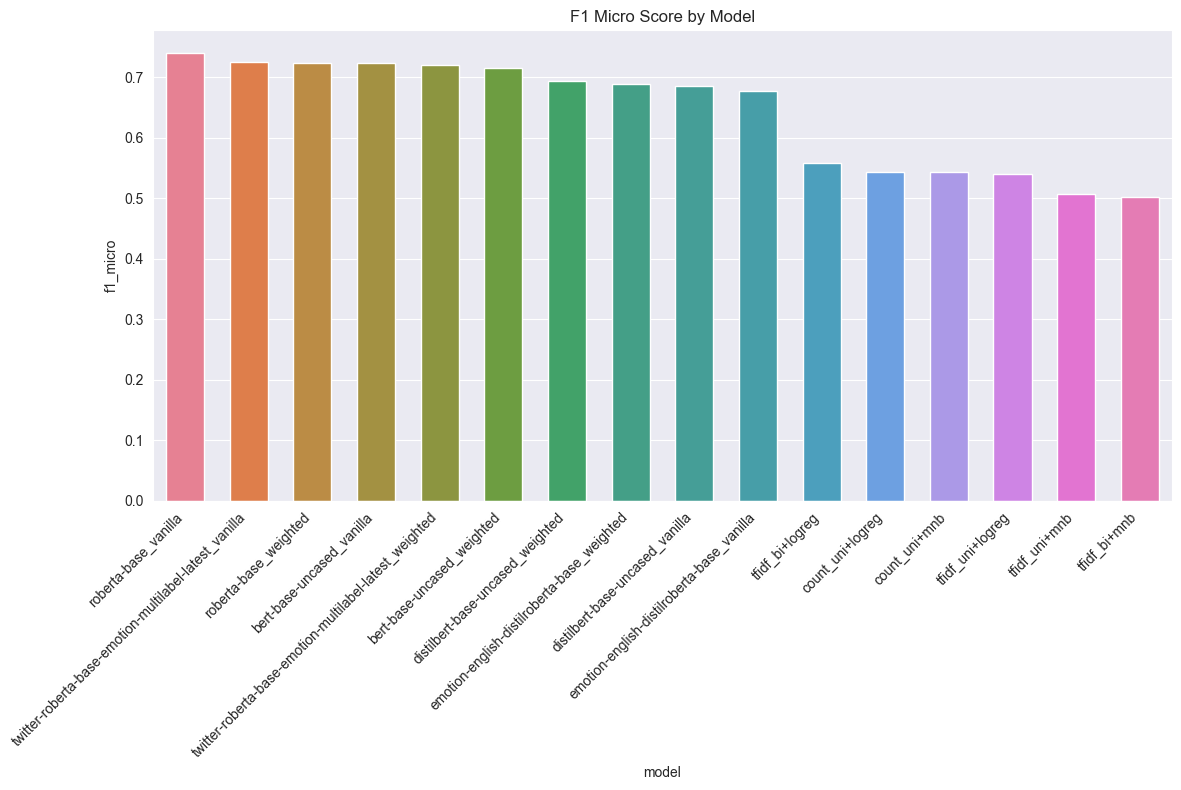

In [38]:
plt.figure(figsize=(12, 8))
sns.barplot(x='model', y='f1_micro', hue='model', data=all_results_sorted, legend=False, width=0.6)
plt.title('F1 Micro Score by Model')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Conclusion

In this notebook, we've:
1. Analyzed the distribution of emotions in our dataset
2. Preprocessed text data for NLP tasks
3. Built multiple baseline models using traditional machine learning
4. Implemented advanced transformer-based models
5. Compared performance across all approaches

The transformer models typically offer superior performance due to their ability to understand context and semantic meaning, though at the cost of higher computational requirements. Traditional ML approaches like TF-IDF with Logistic Regression provide a strong baseline with much faster training times.
